# Neuroblastoma xenografts — prepare eight tumors for comparison

Jiang and colleagues compared control diet, retinoic acid (RA), niclosamide ethanolamine (NEN), and their combination in human SK-N-BE(2) xenografts. Their published RNA velocity field points from cycling neuroblasts toward neuron-like cells through intermediate states. We start by asking which parts of that comparison can be reproduced from the deposited matrices. Each tumor is one biological replicate. [Study and Figure 6](https://doi.org/10.1073/pnas.2502483122) · [GSE288099](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE288099)

The first run downloads about 2.5 GiB. Run this notebook before the four-condition MultiScorer example.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "benchmarks/validation/neuroblastoma_expression.py").exists()
)
sys.path.insert(0, str(PROJECT))
# The helper is available once the source checkout is on sys.path.
from benchmarks.validation.neuroblastoma_inputs import public_manifest  # noqa: E402

DATA = PROJECT / "data/neuroblastoma"
OUT = PROJECT / "tutorial_outputs/neuroblastoma"
OUT.mkdir(parents=True, exist_ok=True)
GROUPS = ["CTRL", "RA", "NEN", "RA+NEN"]
manifest = public_manifest()[["sample","library","condition","biological_replicate"]]
display(manifest)

,sample,library,condition,biological_replicate
0,GSM8758977,C1,CTRL,1
1,GSM8758978,C2,CTRL,2
2,GSM8758979,R1,RA,1
3,GSM8758980,R2,RA,2
4,GSM8758981,N1,NEN,1
5,GSM8758982,N2,NEN,2
6,GSM8758983,RN1,RA+NEN,1
7,GSM8758984,RN2,RA+NEN,2


## Check the deposited molecular measurements

The sample files contain human-reference gene expression for a large number of barcodes, including low-count droplets. The authors analyzed 14,938 cells after their selection. Here we show our own selection and denominator. Separate spliced and unspliced molecules are available in principle from the raw PIP-seq reads. The expression matrix contains total gene counts. The run inventory below comes from the [ENA project record](https://www.ebi.ac.uk/ena/browser/view/PRJNA1216192). It records the raw-read URLs and checksums for each tumor. Only the GEO expression files are downloaded for this notebook.

In [2]:
from benchmarks.validation.neuroblastoma_expression import geo_input
first = manifest.iloc[0]
features = pd.read_csv(
    geo_input(DATA, first["sample"], first.library, "features.tsv"), sep="\t", header=None
)
display(features[2].value_counts().rename("features").to_frame())
run_manifest = PROJECT / "tutorials" / "resources" / "GSE288099_fastq_manifest.tsv"
runs = pd.read_csv(run_manifest, sep="\t")
assert set(runs.sample_alias) == set(manifest["sample"]) and runs.run_accession.is_unique
runs["compressed_GB"] = runs.fastq_bytes.map(lambda s: sum(map(int,s.split(";"))) / 1e9)
display(
    runs.groupby("sample_alias")
    .agg(runs=("run_accession", "size"), compressed_GB=("compressed_GB", "sum"))
    .round(2)
)
runs.to_csv(OUT / "fastq_manifest.tsv", sep="\t", index=False)

,features
2,
Gene Expression,37468


,runs,compressed_GB
sample_alias,,
GSM8758977,3,49.21
GSM8758978,3,58.26
GSM8758979,3,59.96
GSM8758980,3,72.91
GSM8758981,3,64.75
GSM8758982,3,60.90
GSM8758983,3,63.62
GSM8758984,3,54.53


## Select reproducible neural-lineage profiles

Require ≥1,500 counts, ≥700 detected genes, ≤20% mitochondrial counts and detection of at least two of *PHOX2B, UCHL1, CHGA, CHGB, NCAM1, ELAVL4*. This enriches neural profiles. Human-reference counts alone cannot distinguish every cross-mapped host read or establish malignancy. Save depth and two module scores per eligible barcode. Each score is the mean log(1 + counts per 10,000) across its listed genes. Reserve *NEFL, STMN2, MCM2, PCNA* for a separate expression check.

To give each tumor the same opportunity to contribute neighbors, sample up to 800 eligible profiles per tumor uniformly with a reproducible sample-specific seed. The full eligible set remains available for composition summaries.

In [3]:
from benchmarks.validation.neuroblastoma_expression import CYCLING, NEURON, read_tumor

samples, eligible, inventory = [], [], []
for row in manifest.itertuples():
    sample, metadata, audit = read_tumor(DATA, row.sample, row.library, row.condition)
    samples.append(sample)
    eligible.append(metadata)
    inventory.append(audit)
audit = pd.DataFrame(inventory)
display(audit)
all_profiles = pd.concat(eligible)
sampled = ad.concat(samples, join="inner", merge="same")
assert sampled.obs_names.is_unique and len(all_profiles) == audit.neural_profiles.sum()
all_profiles.to_csv(OUT / "eligible_profiles.csv.gz")
audit.to_csv(OUT / "tumor_inventory.csv", index=False)
sampled.write_h5ad(OUT / "expression.h5ad", compression="gzip")
print("Neuronal module:", NEURON, "\nCycling module:", CYCLING)

Neuronal module: ['TUBB3', 'NEFM', 'DCX', 'GAP43', 'TH', 'MAP2'] 
Cycling module: ['MKI67', 'TOP2A', 'UBE2C', 'CENPF', 'BIRC5', 'CDK1']


,tumor,condition,barcodes,pass_qc,neural_profiles,modeled
0,C1,CTRL,1466644,17216,13802,800
1,C2,CTRL,1566011,14126,11931,800
2,R1,RA,1883692,16990,15439,800
3,R2,RA,1869710,20133,18674,800
4,N1,NEN,1619913,23535,21931,800
5,N2,NEN,1444743,19168,17889,800
6,RN1,RA+NEN,1499883,19461,18015,800
7,RN2,RA+NEN,1484192,18332,16745,800


## Check the observed differentiation axis per tumor

A positive balance means stronger expression of the neuronal panel relative to the cycling panel. Compute one mean per tumor on all eligible cells. Single-cell expression scores characterize sampled populations and carry no units of differentiation rate.

neuronal_score  cycling_score  balance      depth
condition tumor                                                   
CTRL      C1              0.721          0.580    0.141   8138.751
          C2              0.644          0.451    0.193  10366.155
NEN       N1              0.562          0.559    0.002   8089.250
          N2              0.617          0.567    0.050   9416.226
RA        R1              0.751          0.581    0.169   8780.356
          R2              0.768          0.592    0.176   9974.073
RA+NEN    RN1             0.753          0.645    0.109  10149.904
          RN2             0.752          0.665    0.087   8435.605

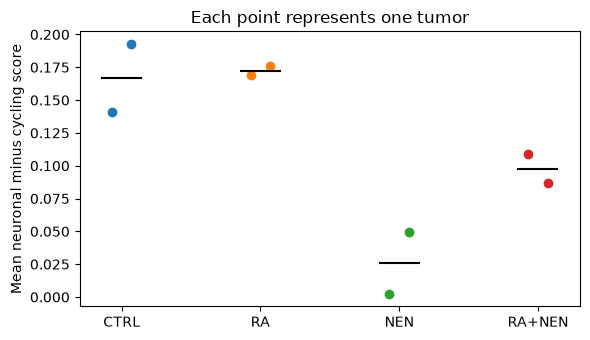

In [4]:
tumors = all_profiles.groupby(["condition", "tumor"])[
    ["neuronal_score", "cycling_score", "balance", "depth"]
].mean()
display(tumors.round(3))
fig, ax = plt.subplots(figsize=(6,3.5))
for i, g in enumerate(GROUPS):
    y = tumors.loc[g,"balance"].to_numpy()
    ax.scatter(i + np.linspace(-.07,.07,len(y)), y)
    ax.plot([i-.14,i+.14],[y.mean()]*2,color="black")
ax.set(
    xticks=range(4),
    xticklabels=GROUPS,
    ylabel="Mean neuronal minus cycling score",
    title="Each point represents one tumor",
)
fig.tight_layout()
plt.show()

The eight deposited matrices contain 12,834,788 barcode columns. The thresholds above select 134,426 neural-marker-positive profiles and retain 6,400 for the shared graph. The authors analyzed 14,938 cells with their own cell selection and annotation. These different denominators matter when comparing the fraction of neuronal cells across studies. Notebook 24 reports endpoint frequencies on the full eligible set and graph metrics on the balanced sample.

## Recover a directional graph from sequencing reads

The FASTQ manifest above supplies both read URLs, checksums and tumor assignments. Combine the three sequencing runs from each tumor as technical lanes. Process them with the PIP-seq V chemistry and the same human–mouse reference and matching annotation for every arm. Retain the mapping between processed barcodes and the GEO identifiers. Resolve host profiles and ambiguous species assignments using the joint alignment. The published GEO barcode strings may use different identifiers from the native PIP-seq reads.

For example, with lane FASTQs named for the PIPseeker input convention, the vendor workflow takes `pipseeker full --fastq <FASTQ-prefix> --chemistry v5 --star-index-path <joint-STAR-index> --output-path <tumor-output>`. Verify that aligned reads carry corrected cell and UMI tags before counting spliced/unspliced molecules with velocyto. The [PIPseeker guide](https://fbs-public.s3.us-east-2.amazonaws.com/public-pipseeker-releases/pipseeker-v3.1.3/PIPseeker-v3.1-User-Guide.pdf) documents the input layout. The [alignment audit](../neuroblastoma_data.rst) shows the tagged-BAM checks and count command.

Use the matched-loom fitting command in the alignment guide to estimate dynamical RNA velocity from the eight species-verified loom files and their barcode crosswalk. For the matched sensitivity calculation in notebook 24, supply an AnnData with the identical modeled cell IDs, genuine count layers called `spliced` and `unspliced`, and a row-stochastic fitted velocity transition matrix in `obsp["T_velocity"]`. Setting `SCCS_NEUROBLASTOMA_VELOCITY_H5AD` selects that input. If species-aware filtering changes the eligible cells, rebuild the matched expression subset first. The next notebook runs the expression-neighborhood reference directly from the eight measured matrices.